In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv("../.env")
url = (f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
       f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}")
engine = create_engine(url)

sns.set_theme(style="whitegrid")
pd.read_sql("SELECT COUNT(*) AS telemetry_rows FROM telemetry", engine)

,telemetry_rows
0,876100


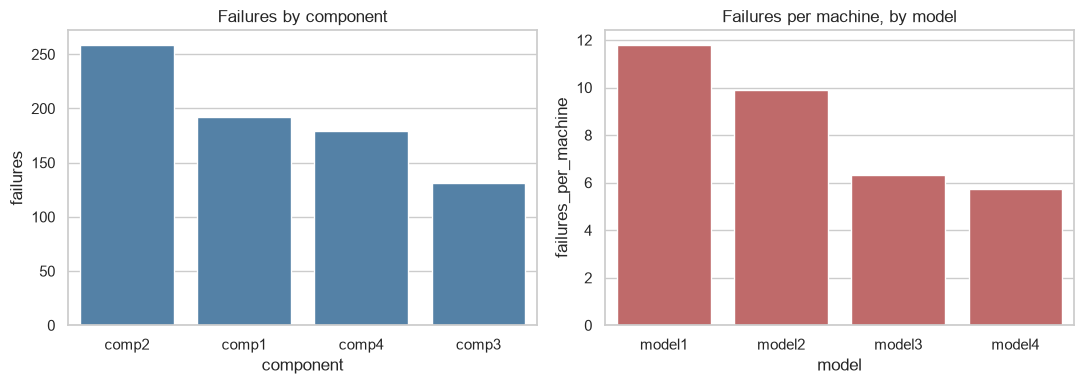

In [2]:
fail_comp = pd.read_sql("""
    SELECT failure AS component, COUNT(*) AS failures
    FROM failures GROUP BY failure ORDER BY failures DESC
""", engine)

fail_model = pd.read_sql("""
    SELECT m.model,
           ROUND(COUNT(f.id)::numeric / COUNT(DISTINCT m.machine_id), 2) AS failures_per_machine
    FROM machines m LEFT JOIN failures f USING (machine_id)
    GROUP BY m.model ORDER BY m.model
""", engine)
fail_model["failures_per_machine"] = fail_model["failures_per_machine"].astype(float)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=fail_comp, x="component", y="failures", ax=ax[0], color="steelblue")
ax[0].set_title("Failures by component")
sns.barplot(data=fail_model, x="model", y="failures_per_machine", ax=ax[1], color="indianred")
ax[1].set_title("Failures per machine, by model")
plt.tight_layout()
plt.show()

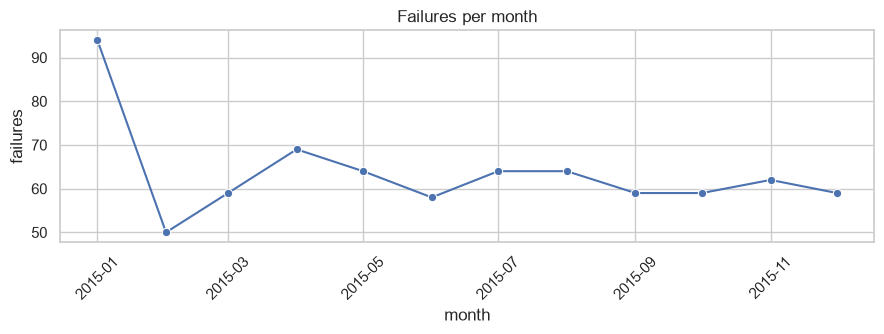

In [3]:
monthly = pd.read_sql("""
    SELECT DATE_TRUNC('month', datetime)::date AS month, COUNT(*) AS failures
    FROM failures GROUP BY 1 ORDER BY 1
""", engine)

plt.figure(figsize=(9, 3.5))
sns.lineplot(data=monthly, x="month", y="failures", marker="o")
plt.title("Failures per month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

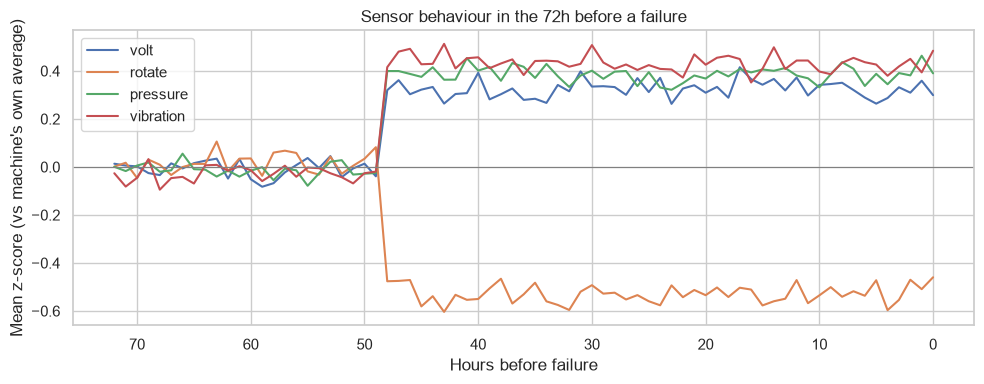

In [4]:
tele = pd.read_sql("SELECT * FROM telemetry", engine, parse_dates=["datetime"])
fails = pd.read_sql(
    "SELECT DISTINCT machine_id, datetime AS fail_ts FROM failures", engine,
    parse_dates=["fail_ts"])

sensors = ["volt", "rotate", "pressure", "vibration"]

# z-score each sensor within each machine, so machines are comparable
tele[sensors] = tele.groupby("machine_id")[sensors].transform(
    lambda s: (s - s.mean()) / s.std())

tele = tele.set_index(["machine_id", "datetime"]).sort_index()

rows = []
for m_id, ts in zip(fails["machine_id"], fails["fail_ts"]):
    window = tele.loc[m_id].loc[ts - pd.Timedelta(hours=72): ts]
    if len(window) == 0:
        continue
    window = window.copy()
    window["hours_before"] = ((ts - window.index) / pd.Timedelta(hours=1)).astype(int)
    rows.append(window[sensors + ["hours_before"]])

pre = pd.concat(rows)
profile = pre.groupby("hours_before")[sensors].mean().sort_index(ascending=False)

profile.plot(figsize=(10, 4))
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Hours before failure")
plt.ylabel("Mean z-score (vs machine's own average)")
plt.title("Sensor behaviour in the 72h before a failure")
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

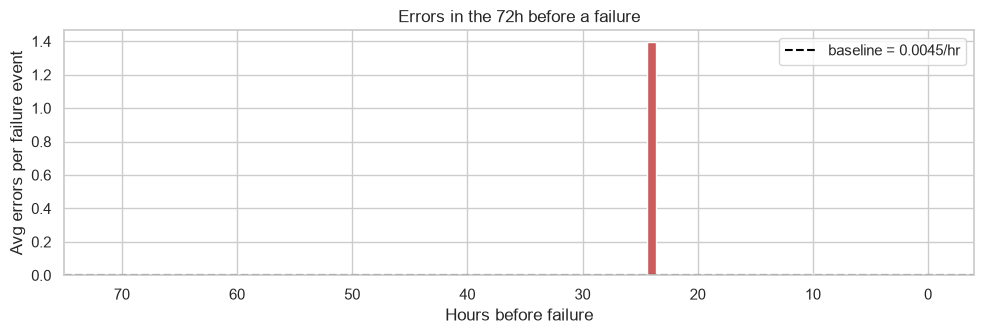

In [5]:
errors = pd.read_sql("SELECT machine_id, datetime FROM errors", engine,
                     parse_dates=["datetime"])

counts = []
for m_id, ts in zip(fails["machine_id"], fails["fail_ts"]):
    e = errors[(errors.machine_id == m_id)
               & (errors.datetime > ts - pd.Timedelta(hours=72))
               & (errors.datetime <= ts)]
    hb = ((ts - e["datetime"]) / pd.Timedelta(hours=1)).astype(int)
    counts.append(hb)

hb_all = pd.concat(counts)
per_hour = hb_all.value_counts().reindex(range(0, 72), fill_value=0).sort_index()
per_hour = per_hour / len(fails)   # average errors per failure event per hour

# baseline: errors per machine per hour over the whole year
baseline = len(errors) / (100 * 8761)

plt.figure(figsize=(10, 3.5))
plt.bar(per_hour.index, per_hour.values, color="indianred")
plt.axhline(baseline, color="black", ls="--", label=f"baseline = {baseline:.4f}/hr")
plt.xlabel("Hours before failure")
plt.ylabel("Avg errors per failure event")
plt.title("Errors in the 72h before a failure")
plt.gca().invert_xaxis()
plt.legend()
plt.tight_layout()
plt.show()

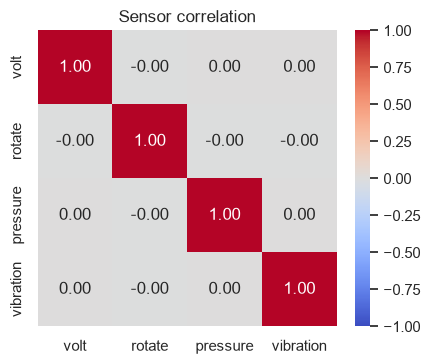

In [6]:
raw = pd.read_sql("SELECT volt, rotate, pressure, vibration FROM telemetry", engine)
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(raw.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Sensor correlation")
plt.tight_layout()
plt.show()

Share of failure events with vibration shift > 0.2 SD: 0.3


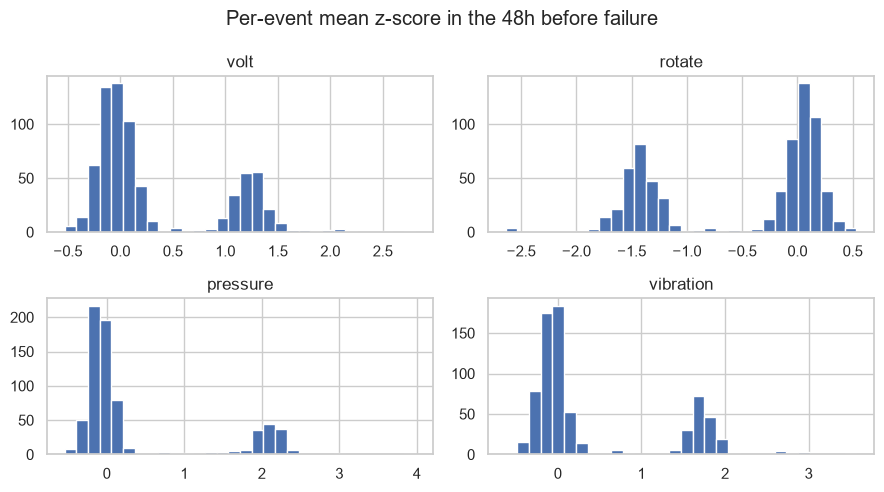

In [7]:
ev_means = []
for m_id, ts in zip(fails["machine_id"], fails["fail_ts"]):
    w = tele.loc[m_id].loc[ts - pd.Timedelta(hours=47): ts]
    if len(w):
        ev_means.append(w[sensors].mean())
ev = pd.DataFrame(ev_means)

print("Share of failure events with vibration shift > 0.2 SD:",
      round((ev["vibration"] > 0.2).mean(), 3))
ev[sensors].hist(bins=30, figsize=(9, 5))
plt.suptitle("Per-event mean z-score in the 48h before failure")
plt.tight_layout()
plt.show()

In [8]:
fails_c = pd.read_sql(
    "SELECT machine_id, datetime AS fail_ts, failure AS comp FROM failures",
    engine, parse_dates=["fail_ts"])

rows = []
for m_id, ts, comp in zip(fails_c.machine_id, fails_c.fail_ts, fails_c.comp):
    w = tele.loc[m_id].loc[ts - pd.Timedelta(hours=47): ts]
    if len(w):
        r = w[sensors].mean().to_dict()
        r["comp"] = comp
        rows.append(r)

evc = pd.DataFrame(rows)
evc["shifted"] = evc["vibration"] > 1.0   # valley between the two bumps
print(evc.groupby("comp")["shifted"].agg(count="count", share_shifted="mean").round(3))

       count  share_shifted
comp                       
comp1    192          0.047
comp2    259          0.077
comp3    131          0.046
comp4    179          1.000


## Key findings (Azure PdM, simulated data)

1. comp2 is the most frequent failure (34%); model1 machines fail about 2x more per machine than model4 (11.8 vs 5.7).
2. MTBF is lowest for model1 (~32 days) and highest for model4 (~61 days). Machines aged 15+ show the most failures per machine (9.5), but the age trend is not monotonic.
3. Each component has an error signature exactly 24h before failure (comp1: error1, comp2: error2 AND error3 in the same hour, comp3: error4, comp4: error5), covering ~97-99% of failures. error2 or error3 alone never precede a failure (0 of 1,311 events).
4. Sensor drift (volt, pressure, vibration up; rotate down) starts ~48h before failure and is specific to comp4 (100% of its failures, vs ~5-8% for other components).
5. Most errors are background noise: only ~26% of all errors precede a failure. By pattern, error5 alone is followed by failure 46% of the time, error1 and error4 alone only ~16%, so alerting on any single error would produce many false alarms.
6. Caveats: the data is synthetic, so such clean lead times will not appear in real factories. Downtime cost uses assumed values (8 h per failure, 2000 per hour).